# SINASC 2024 — comparabilidade dos grupos e suporte comum na capital paulista
**IPT — Mestrado em Computação Aplicada — Big Data & Analytics**

Diagnóstico de **comparabilidade observável** entre gestantes que iniciaram o pré-natal no 1º trimestre (T=1) e nos meses 4–6 (T=0), residentes no município de São Paulo, nascimentos de 2024. **Não há estimação de efeito causal**: nenhum AIPW, ATT ou ATE, nenhum pareamento, ponderação ou recorte de suporte. O peso ao nascer (desfecho) não é usado em nenhuma etapa — o diagnóstico é feito "às cegas" em relação ao desfecho, como recomenda a fase de desenho de estudos observacionais.

Recorte geográfico decidido na etapa anterior: [qualidade_sp_2014_2024.ipynb](../qualidade_geografica_2024/qualidade_sp_2014_2024.ipynb). Execute com a **.venv deste projeto** (`.venv/Scripts/python.exe`). Saídas gravadas apenas nesta pasta: `balanco_covariaveis_2024.csv` e `resumo_propensity_2024.csv`.

## 1. Contexto metodológico

- **Pergunta desta etapa:** as características maternas registradas são suficientemente parecidas entre T=1 e T=0, e existe suporte comum no escore de propensão estimado, para justificar a estimação causal?
- **Unidade:** registro de nascido vivo (uma Declaração de Nascido Vivo); não é coorte de gestantes.
- **Balanço:** diferença média padronizada (SMD). Numérica: $(\bar x_1-\bar x_0)/\sqrt{(s_1^2+s_0^2)/2}$, com variâncias amostrais (ddof=1). Categórica: cada nível é tratado como indicador binário, $(p_1-p_0)/\sqrt{[p_1(1-p_1)+p_0(1-p_0)]/2}$, com $p_g$ = proporção do nível entre **todos** os elegíveis do grupo $g$ (o nível "Ignorado/ausente" entra no denominador e aparece como linha própria). O resumo de cada variável categórica é o **maior |SMD| entre seus níveis** — mesma regra de `src/diagnosticos.py::calcular_smd`.
- **Referências visuais 0,1 e 0,2** são convenções da literatura, não testes. SMD pequeno não garante ausência de confundimento; p-valores não são usados, pois com ~115 mil registros qualquer diferença trivial seria "significativa".
- **Escore de propensão:** $e(x)=P(T=1\mid X=x)$ por regressão logística com penalização L2 (C=1), sem pesos de classe, com predições fora da partição de treino (5 partições estratificadas, semente 20240925). Reutiliza `construir_pipeline_propensity` e `estimar_propensity_oof` de `src/diagnosticos.py`.
- **Suporte comum observado nos escores estimados não comprova ignorabilidade nem identificação causal**: só diz respeito às covariáveis incluídas e ao modelo usado.

In [1]:
from pathlib import Path
import sys
import json
import base64
sys.dont_write_bytecode = True

import duckdb
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import sklearn
from IPython.display import display, Markdown

cwd = Path.cwd().resolve()
raiz = next(p for p in [cwd, *cwd.parents]
            if (p / "src" / "visualizacao.py").is_file()
            and (p / "data" / "processed").is_dir())
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
# _criar_views contém a projeção SQL congelada das covariáveis do contrato principal.
from src.amostra import _criar_views
from src.diagnosticos import (calcular_smd, estimar_propensity_oof,
                              resumir_overlap, validar_colunas_propensity)
from src.visualizacao import CORES_IPT, aplicar_tema_base

PARQUET = raiz / "data" / "processed" / "sinasc_2024.parquet"
PASTA = raiz / "outputs" / "comparabilidade_sp_capital_2024"
CSV_BALANCO = PASTA / "balanco_covariaveis_2024.csv"
CSV_PROPENSITY = PASTA / "resumo_propensity_2024.csv"
MUNICIPIO = "355030"
ESPERADO = {"n": 114_694, "t1": 104_576, "t0": 10_118}
assert PARQUET.is_file(), f"Base local ausente: {PARQUET}"
assert PASTA.is_dir(), f"Pasta de entrega ausente: {PASTA}"

def fmt(valor, casas=0):
    """Número no padrão brasileiro (milhar com ponto, decimal com vírgula)."""
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "_").replace(".", ",").replace("_", ".")

def exibir_plotly(figura):
    # PNG de apoio e representação interativa na mesma saída, sem arquivos extras.
    png = figura.to_image(format="png", scale=1.5)
    display({
        "application/vnd.plotly.v1+json": json.loads(pio.to_json(figura)),
        "image/png": base64.b64encode(png).decode("ascii"),
        "text/plain": figura.layout.title.text,
    }, raw=True)

print("Ambiente:", sys.executable)
print("Versões: DuckDB", duckdb.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)
print("Base:", PARQUET.relative_to(raiz).as_posix())

Ambiente: C:\GitHub\data-science-projects\projetos\big-data-sinasc-causal-ml\.venv\Scripts\python.exe
Versões: DuckDB 1.5.5 | pandas 3.0.6 | scikit-learn 1.8.0
Base: data/processed/sinasc_2024.parquet


## 2. População analisada

Nascimentos de 2024 com mãe residente no município de São Paulo (`CODMUNRES=355030`), especificação B:

| Critério | Regra |
|---|---|
| Gestação única | `GRAVIDEZ=1` |
| Peso | inteiro entre 500 e 6.000 g (somente para elegibilidade; não usado como preditor) |
| T=1 | `MESPRENAT` 1–3 |
| T=0 | `MESPRENAT` 4–6 (meses 7–9 ficam fora da população) |

Covariáveis incompletas não excluem registros. A consulta reaproveita a projeção congelada de `src/amostra.py` e acrescenta apenas o filtro de município e de meses 1–6. Divergência em relação à referência interrompe a execução.

In [2]:
with duckdb.connect() as con:
    _criar_views(con, PARQUET)
    sql_view = con.execute(
        "SELECT sql FROM duckdb_views() WHERE view_name = 'amostra_principal'"
    ).fetchone()[0]
    projecao = sql_view[sql_view.index(" AS SELECT ") + 4: sql_view.index(" FROM fase1_base")]
    consulta = (
        projecao
        + ", mesprenat_num, peso_num, CAST(CODMUNRES AS VARCHAR) AS CODMUNRES"
        + " FROM fase1_base"
        + " WHERE tratamento IS NOT NULL AND y_p1 IS NOT NULL AND gravidez_num = 1"
        + " AND mesprenat_num BETWEEN 1 AND 6 AND CAST(CODMUNRES AS VARCHAR) = ?"
        + " ORDER BY contador"
    )
    dados = con.execute(consulta, [MUNICIPIO]).df()
    datas_fora = con.execute(
        "SELECT count(*) FILTER (WHERE d IS NULL OR year(d) <> 2024) FROM ("
        " SELECT try_strptime(DTNASC, '%d%m%Y') AS d FROM sinasc"
        " WHERE CAST(CODMUNRES AS VARCHAR) = ?)", [MUNICIPIO]
    ).fetchone()[0]

# O desfecho não participa deste diagnóstico de desenho.
dados = dados.drop(columns=["Y_BAIXO_PESO"])
dados["tratamento"] = dados["tratamento"].astype(int)
n_total, n_t1 = len(dados), int(dados.tratamento.eq(1).sum())
n_t0 = n_total - n_t1

assert {"n": n_total, "t1": n_t1, "t0": n_t0} == ESPERADO, (n_total, n_t1, n_t0)
assert dados.contador.notna().all() and dados.contador.is_unique, "Chave contador inválida."
assert dados.tratamento.eq(dados.mesprenat_num.le(3).astype(int)).all()
assert dados.peso_num.between(500, 6000).all()
assert dados.CODMUNRES.eq(MUNICIPIO).all() and dados.UF_RESIDENCIA.eq("35").all()
assert datas_fora == 0, "Há datas de nascimento ausentes ou fora de 2024."

populacao = pd.DataFrame({
    "Grupo": ["T=1 (meses 1–3)", "T=0 (meses 4–6)", "Total"],
    "Nascimentos": [fmt(n_t1), fmt(n_t0), fmt(n_total)],
    "% do total": [fmt(100 * n_t1 / n_total, 2), fmt(100 * n_t0 / n_total, 2), "100,00"],
})
display(populacao.set_index("Grupo"))
print("Distribuição de MESPRENAT:", dados.mesprenat_num.value_counts().sort_index().to_dict())
print("Contagens conferidas com a referência; chave única; datas em 2024.")

,Nascimentos,% do total
Grupo,,
T=1 (meses 1–3),104.576,"91,18"
T=0 (meses 4–6),10.118,"8,82"
Total,114.694,"100,00"


Distribuição de MESPRENAT: {1: 35224, 2: 54444, 3: 14908, 4: 5366, 5: 3005, 6: 1747}
Contagens conferidas com a referência; chave única; datas em 2024.


## 3. Covariáveis: validade, temporalidade e decisão

Todas as covariáveis são **registradas no parto**, não no momento do início do pré-natal. Para as variáveis abaixo, a premissa do contrato é que representam condições anteriores à exposição; a tabela registra onde essa premissa é mais frágil. Códigos ignorados nunca são interpretados como categoria substantiva: aparecem como "Ignorado/ausente" e, no modelo, funcionam apenas como indicador de ausência.

| Covariável | Campo | Codificação usada | Temporalidade / validade | Escore de propensão |
|---|---|---|---|---|
| Idade materna | `IDADEMAE` | numérica; fora de 10–59 → ausente (imputação por mediana com indicador) | medida no parto; difere da idade no início da gestação em menos de um ano | incluída (linear) |
| Escolaridade | `ESCMAE2010` | 0–5; 9/nulo → Ignorado | aproximação de posição socioeconômica; em adolescentes pode mudar durante a gestação | incluída |
| Raça/cor | `RACACORMAE` | 1–5; 9/nulo → Ignorado (código 9 não confirmado no dicionário) | atributo estável | incluída |
| Situação conjugal | `ESTCIVMAE` | 1–5; 9/nulo → Ignorado | **temporalidade mais frágil**: casamento/união pode ocorrer depois do início do pré-natal | incluída no contrato; retirada na sensibilidade |
| Paridade | `PARIDADE` | 0 nulípara / 1 multípara | histórico anterior à gestação atual | incluída |
| Perdas fetais anteriores | `QTDFILMORT` | 0 / 1 / 2 ou mais; 99/nulo → Ignorado | histórico anterior, mas mistura perdas espontâneas e abortos (provável sub-registro); limites e sentinela 99 não confirmados no dicionário | incluída com ressalva; retirada na sensibilidade |
| UF de residência | `CODMUNRES` | constante (35) | — | **excluída** (preditor constante no recorte) |

Fora de consideração por serem posteriores ao início do pré-natal, mediadoras ou desfecho: peso ao nascer, idade gestacional (`GESTACAO`, `SEMAGESTAC`), consultas (`CONSULTAS`, `CONSPRENAT`), tipo de parto, Kotelchuck, Apgar, Robson e demais campos do parto — verificado por `validar_colunas_propensity`. Outros campos possivelmente anteriores (`QTDGESTANT`, `QTDFILVIVO`, `IDADEPAI`, `CODOCUPMAE`) **não entram nesta etapa**, para não criar outra versão do conjunto de ajuste.

In [3]:
NUMERICAS = ["IDADEMAE_NUM"]
CATEGORICAS = ["ESCOLARIDADE_MAE", "RACA_COR_MAE", "SITUACAO_CONJUGAL",
               "PARIDADE_CAT", "PERDAS_FETAIS_CAT"]
validar_colunas_propensity([*NUMERICAS, *CATEGORICAS])

ROTULO_VAR = {
    "IDADEMAE_NUM": "Idade materna (anos)",
    "IDADE_FAIXA": "Idade materna (faixa)",
    "ESCOLARIDADE_MAE": "Escolaridade",
    "RACA_COR_MAE": "Raça/cor",
    "SITUACAO_CONJUGAL": "Situação conjugal",
    "PARIDADE_CAT": "Paridade",
    "PERDAS_FETAIS_CAT": "Perdas fetais anteriores",
}
ROTULO_NIVEL = {
    "ESCOLARIDADE_MAE": {"0": "Sem escolaridade", "1": "Fundamental I", "2": "Fundamental II",
                         "3": "Médio", "4": "Superior incompleto", "5": "Superior completo"},
    "RACA_COR_MAE": {"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda", "5": "Indígena"},
    "SITUACAO_CONJUGAL": {"1": "Solteira", "2": "Casada", "3": "Viúva",
                          "4": "Separada/divorciada", "5": "União estável"},
    "PARIDADE_CAT": {"0": "Nulípara", "1": "Multípara"},
    "PERDAS_FETAIS_CAT": {"0": "Nenhuma", "1": "Uma", "2_OU_MAIS": "Duas ou mais"},
    "IDADE_FAIXA": {"10-19": "10–19 anos", "20-34": "20–34 anos", "35-59": "35–59 anos"},
}
ROTULO_NIVEL = {v: {**niveis, "IGNORADO": "Ignorado/ausente"} for v, niveis in ROTULO_NIVEL.items()}

dados["IDADE_FAIXA"] = pd.cut(dados.IDADEMAE_NUM, [9, 19, 34, 59],
                              labels=["10-19", "20-34", "35-59"]).astype("string").fillna("IGNORADO")

ausencias = pd.DataFrame({
    "Covariável": [ROTULO_VAR[c] for c in [*NUMERICAS, *CATEGORICAS]],
    "Ignorado/ausente (n)": [int(dados.IDADEMAE_NUM.isna().sum())]
                            + [int(dados[c].eq("IGNORADO").sum()) for c in CATEGORICAS],
})
ausencias["% dos elegíveis"] = (100 * ausencias["Ignorado/ausente (n)"] / n_total).map(lambda v: fmt(v, 3))
display(ausencias.set_index("Covariável"))
print("Idade fora de 10–59 imputada pela mediana (com indicador) no modelo:",
      int(dados.IDADEMAE_NUM.isna().sum()), "registros.")

,Ignorado/ausente (n),% dos elegíveis
Covariável,,
Idade materna (anos),0,"0,000"
Escolaridade,24,"0,021"
Raça/cor,42,"0,037"
Situação conjugal,83,"0,072"
Paridade,0,"0,000"
Perdas fetais anteriores,28,"0,024"


Idade fora de 10–59 imputada pela mediana (com indicador) no modelo: 0 registros.


## 4. Perfil dos grupos e diferenças padronizadas

Percentuais por coluna (denominador = elegíveis de cada grupo). Diferença em pontos percentuais = T=1 − T=0; SMD positivo indica nível mais frequente (ou média maior) em T=1. As faixas de idade são **apenas descritivas** — o modelo usa a idade linear — e servem para ver onde a diferença de idade se concentra.

In [4]:
grupo1 = dados.loc[dados.tratamento.eq(1)]
grupo0 = dados.loc[dados.tratamento.eq(0)]

def smd_proporcao(p1, p0):
    variancia = (p1 * (1 - p1) + p0 * (1 - p0)) / 2
    return 0.0 if variancia == 0 else float((p1 - p0) / np.sqrt(variancia))

linhas = []
i1, i0 = grupo1.IDADEMAE_NUM.dropna(), grupo0.IDADEMAE_NUM.dropna()
smd_idade = calcular_smd(dados, "tratamento", NUMERICAS, []).smd.iloc[0]
linhas.append({
    "variavel": "IDADEMAE_NUM", "rotulo_variavel": ROTULO_VAR["IDADEMAE_NUM"],
    "tipo_linha": "numerica", "nivel": "", "rotulo_nivel": "Média (DP)",
    "n_t1": len(i1), "pct_t1": np.nan, "n_t0": len(i0), "pct_t0": np.nan,
    "media_t1": i1.mean(), "dp_t1": i1.std(ddof=1), "media_t0": i0.mean(), "dp_t0": i0.std(ddof=1),
    "mediana_t1": i1.median(), "mediana_t0": i0.median(),
    "diferenca": i1.mean() - i0.mean(), "unidade_diferenca": "anos",
    "smd": smd_idade, "smd_abs": abs(smd_idade),
    "razao_variancias": i1.var(ddof=1) / i0.var(ddof=1), "incluida_propensity": True,
})

for variavel in ["IDADE_FAIXA", *CATEGORICAS]:
    niveis = sorted(set(dados[variavel]), key=lambda n: (n == "IGNORADO", n))
    for nivel in niveis:
        k1, k0 = int(grupo1[variavel].eq(nivel).sum()), int(grupo0[variavel].eq(nivel).sum())
        p1, p0 = k1 / len(grupo1), k0 / len(grupo0)
        smd = smd_proporcao(p1, p0)
        linhas.append({
            "variavel": variavel, "rotulo_variavel": ROTULO_VAR[variavel],
            "tipo_linha": ("faixa_descritiva" if variavel == "IDADE_FAIXA"
                           else "nivel_ausencia" if nivel == "IGNORADO" else "nivel_categorico"),
            "nivel": nivel, "rotulo_nivel": ROTULO_NIVEL[variavel][nivel],
            "n_t1": k1, "pct_t1": 100 * p1, "n_t0": k0, "pct_t0": 100 * p0,
            "diferenca": 100 * (p1 - p0), "unidade_diferenca": "p.p.",
            "smd": smd, "smd_abs": abs(smd), "incluida_propensity": variavel != "IDADE_FAIXA",
        })
balanco = pd.DataFrame(linhas)

# Resumo por variável: maior |SMD| entre níveis, conferido com src/diagnosticos.py.
referencia = calcular_smd(dados, "tratamento", NUMERICAS, CATEGORICAS).set_index("variavel").smd_abs
resumo = (balanco.loc[balanco.tipo_linha.ne("faixa_descritiva")]
          .groupby(["variavel", "rotulo_variavel"], as_index=False).smd_abs.max()
          .sort_values("smd_abs", ascending=False, ignore_index=True))
assert np.allclose(resumo.set_index("variavel").smd_abs.loc[referencia.index], referencia), \
    "SMD por nível não reconcilia com calcular_smd."
nivel_max = (balanco.loc[balanco.tipo_linha.ne("faixa_descritiva")]
             .sort_values("smd_abs", ascending=False).drop_duplicates("variavel")
             .set_index("variavel").rotulo_nivel)
resumo["nivel_mais_desequilibrado"] = resumo.variavel.map(nivel_max).where(resumo.variavel.ne("IDADEMAE_NUM"), "— (média)")
print("SMD por variável reconciliado com src/diagnosticos.py::calcular_smd.")

tabela = balanco.copy()
def n_pct(n, pct):
    return fmt(n) if pd.isna(pct) else f"{fmt(n)} ({fmt(pct, 1)}%)"
tabela["T=1 (meses 1–3)"] = [
    f"{fmt(r.media_t1, 1)} ({fmt(r.dp_t1, 1)})" if r.tipo_linha == "numerica" else n_pct(r.n_t1, r.pct_t1)
    for r in tabela.itertuples()]
tabela["T=0 (meses 4–6)"] = [
    f"{fmt(r.media_t0, 1)} ({fmt(r.dp_t0, 1)})" if r.tipo_linha == "numerica" else n_pct(r.n_t0, r.pct_t0)
    for r in tabela.itertuples()]
tabela["Diferença T1−T0"] = [f"{fmt(r.diferenca, 2)} {r.unidade_diferenca}" for r in tabela.itertuples()]
tabela["SMD"] = tabela.smd.map(lambda v: fmt(v, 3))
tabela = tabela.rename(columns={"rotulo_variavel": "Variável", "rotulo_nivel": "Nível"})
with pd.option_context("display.max_rows", 100):
    display(tabela.set_index(["Variável", "Nível"])[
        ["T=1 (meses 1–3)", "T=0 (meses 4–6)", "Diferença T1−T0", "SMD"]])
print(f"Idade — mediana T=1: {fmt(balanco.mediana_t1.iloc[0], 0)} | T=0: {fmt(balanco.mediana_t0.iloc[0], 0)}"
      f" | razão de variâncias T1/T0: {fmt(balanco.razao_variancias.iloc[0], 3)}")

SMD por variável reconciliado com src/diagnosticos.py::calcular_smd.


T=1 (meses 1–3) T=0 (meses 4–6)  \
Variável                 Nível                                                 
Idade materna (anos)     Média (DP)               29,3 (6,6)      27,5 (6,9)   
Idade materna (faixa)    10–19 anos             6.889 (6,6%)   1.209 (11,9%)   
                         20–34 anos           71.767 (68,6%)   7.090 (70,1%)   
                         35–59 anos           25.920 (24,8%)   1.819 (18,0%)   
Escolaridade             Sem escolaridade          28 (0,0%)        5 (0,0%)   
                         Fundamental I            579 (0,6%)      113 (1,1%)   
                         Fundamental II         8.727 (8,3%)   1.508 (14,9%)   
                         Médio                56.513 (54,0%)   6.620 (65,4%)   
                         Superior incompleto    6.163 (5,9%)      564 (5,6%)   
                         Superior completo    32.548 (31,1%)   1.302 (12,9%)   
                         Ignorado/ausente          18 (0,0%)        6 (0,1%)   
Raça/cor                 Branca               47.963 (45,9%)   3.655 (36,1%)   
                         Preta                11.419 (10,9%)   1.287 (12,7%)   
                         Amarela                1.193 (1,1%)       62 (0,6%)   
                         Parda                43.839 (41,9%)   5.085 (50,3%)   
                         Indígena                 123 (0,1%)       26 (0,3%)   
                         Ignorado/ausente          39 (0,0%)        3 (0,0%)   
Situação conjugal        Solteira             47.344 (45,3%)   5.975 (59,1%)   
                         Casada               38.130 (36,5%)   1.831 (18,1%)   
                         Viúva                    114 (0,1%)       11 (0,1%)   
                         Separada/divorciada    1.860 (1,8%)      152 (1,5%)   
                         União estável        17.050 (16,3%)   2.144 (21,2%)   
                         Ignorado/ausente          78 (0,1%)        5 (0,0%)   
Paridade                 Nulípara             42.208 (40,4%)   3.279 (32,4%)   
                         Multípara            62.368 (59,6%)   6.839 (67,6%)   
Perdas fetais anteriores Nenhuma              81.527 (78,0%)   8.043 (79,5%)   
                         Uma                  17.923 (17,1%)   1.579 (15,6%)   
                         Duas ou mais           5.101 (4,9%)      493 (4,9%)   
                         Ignorado/ausente          25 (0,0%)        3 (0,0%)   

                                             Diferença T1−T0     SMD  
Variável                 Nível                                        
Idade materna (anos)     Média (DP)                1,82 anos   0,270  
Idade materna (faixa)    10–19 anos               -5,36 p.p.  -0,186  
                         20–34 anos               -1,45 p.p.  -0,031  
                         35–59 anos                6,81 p.p.   0,167  
Escolaridade             Sem escolaridade         -0,02 p.p.  -0,012  
                         Fundamental I            -0,56 p.p.  -0,062  
                         Fundamental II           -6,56 p.p.  -0,206  
                         Médio                   -11,39 p.p.  -0,234  
                         Superior incompleto       0,32 p.p.   0,014  
                         Superior completo        18,26 p.p.   0,452  
                         Ignorado/ausente         -0,04 p.p.  -0,022  
Raça/cor                 Branca                    9,74 p.p.   0,199  
                         Preta                    -1,80 p.p.  -0,056  
                         Amarela                   0,53 p.p.   0,057  
                         Parda                    -8,34 p.p.  -0,168  
                         Indígena                 -0,14 p.p.  -0,032  
                         Ignorado/ausente          0,01 p.p.   0,004  
Situação conjugal        Solteira                -13,78 p.p.  -0,279  
                         Casada                   18,37 p.p.   0,421  
                         Viúva                     0,00 p.p.   0,000  
  

Idade — mediana T=1: 29 | T=0: 27 | razão de variâncias T1/T0: 0,927


In [5]:
resumo_exibicao = resumo.rename(columns={"rotulo_variavel": "Variável", "smd_abs": "|SMD| máximo",
                                         "nivel_mais_desequilibrado": "Nível com maior |SMD|"})
resumo_exibicao["|SMD| máximo"] = resumo_exibicao["|SMD| máximo"].map(lambda v: fmt(v, 3))
display(resumo_exibicao.set_index("Variável")[["|SMD| máximo", "Nível com maior |SMD|"]])

colunas_csv = ["variavel", "rotulo_variavel", "tipo_linha", "nivel", "rotulo_nivel",
               "n_t1", "pct_t1", "n_t0", "pct_t0", "media_t1", "dp_t1", "media_t0", "dp_t0",
               "mediana_t1", "mediana_t0", "diferenca", "unidade_diferenca", "smd", "smd_abs",
               "razao_variancias", "incluida_propensity", "smd_abs_max_variavel"]
saida_balanco = balanco.copy()
saida_balanco["smd_abs_max_variavel"] = saida_balanco.variavel.map(resumo.set_index("variavel").smd_abs)
saida_balanco[colunas_csv].round(6).to_csv(CSV_BALANCO, sep=";", index=False, encoding="utf-8-sig")
print("Gravado:", CSV_BALANCO.relative_to(raiz).as_posix(), "—", len(saida_balanco), "linhas")

,|SMD| máximo,Nível com maior |SMD|
Variável,,
Escolaridade,"0,452",Superior completo
Situação conjugal,"0,421",Casada
Idade materna (anos),"0,270",— (média)
Raça/cor,"0,199",Branca
Paridade,"0,166",Nulípara
Perdas fetais anteriores,"0,041",Uma


Gravado: outputs/comparabilidade_sp_capital_2024/balanco_covariaveis_2024.csv — 29 linhas


## 5. Gráfico de balanço (Love plot)

Diferença padronizada absoluta por nível, sem pareamento ou ponderação. A cor indica o grupo em que o nível é mais frequente; marcadores vazados são níveis "Ignorado/ausente". Variáveis ordenadas pelo maior |SMD|.

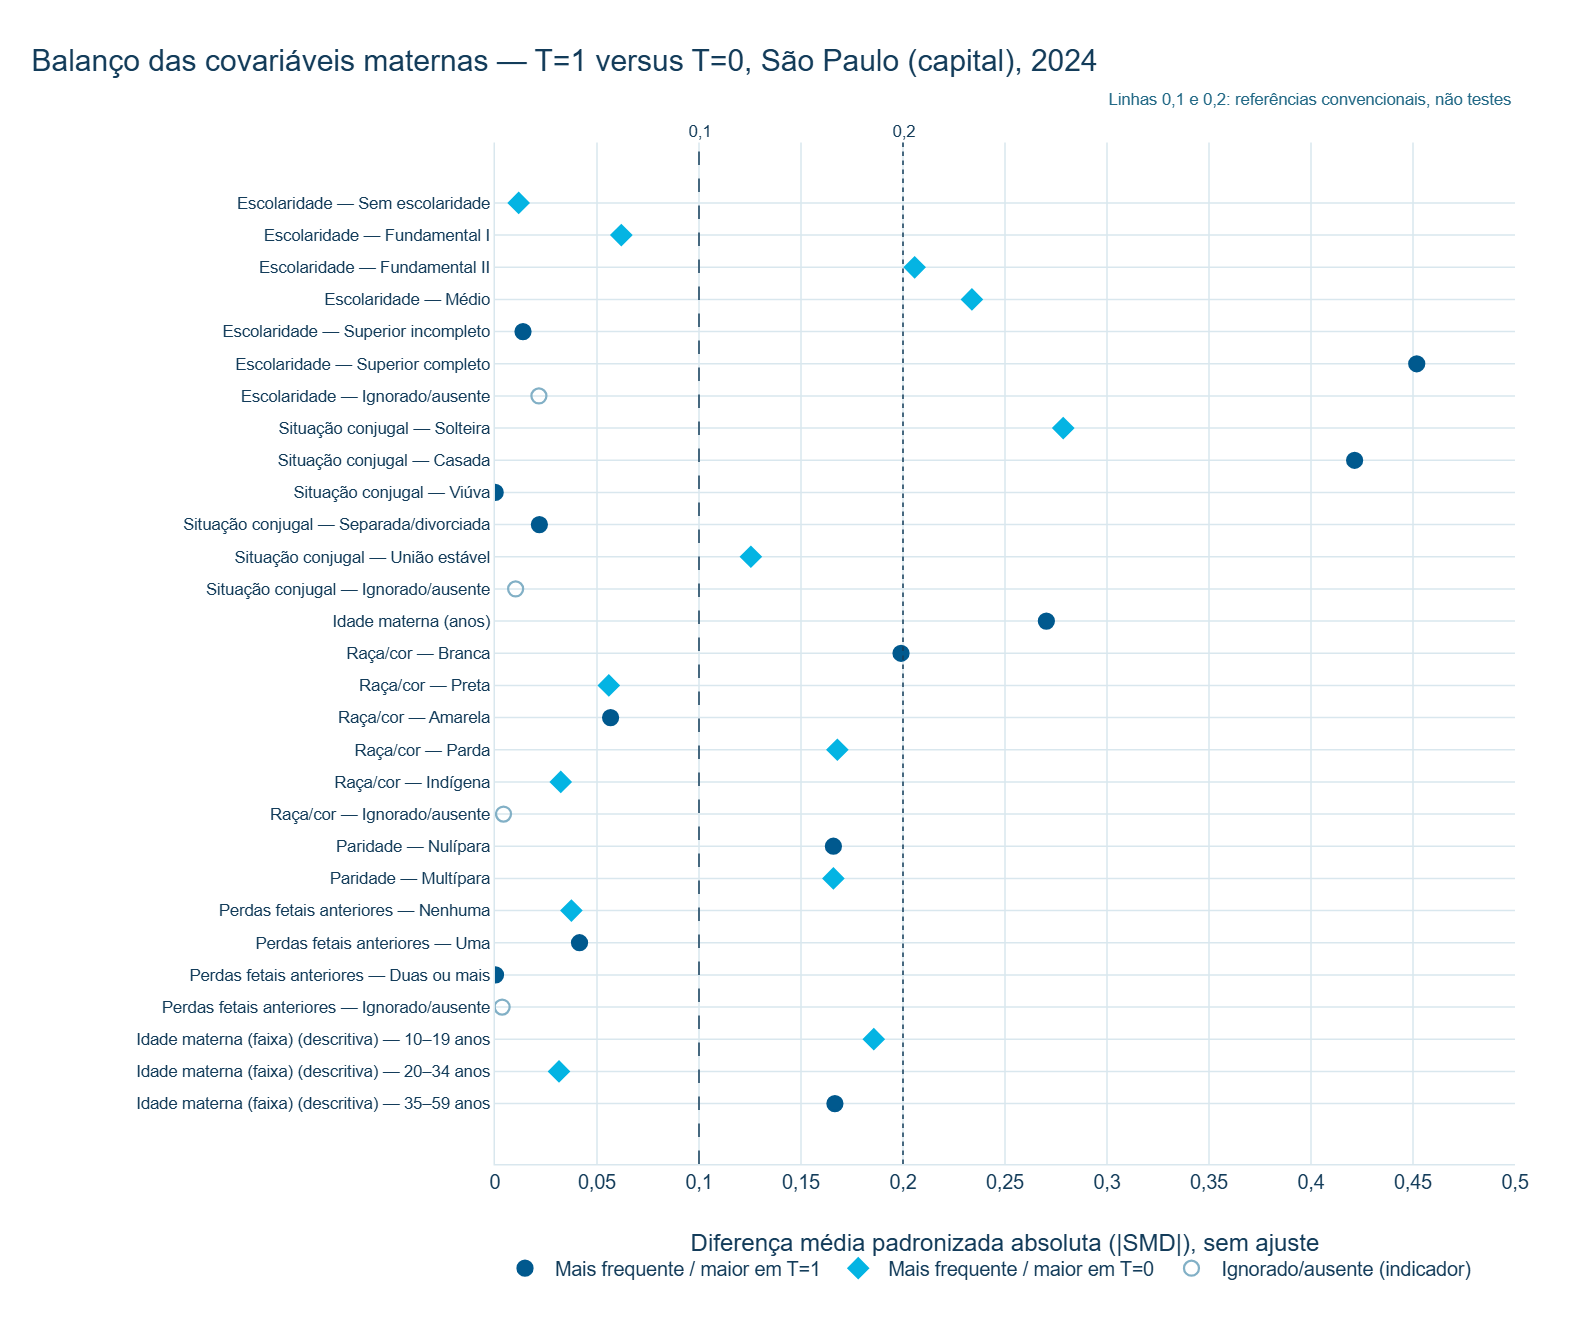

In [6]:
ordem_vars = [*resumo.variavel, "IDADE_FAIXA"]
plot = balanco.copy()
plot["ordem_var"] = plot.variavel.map({v: i for i, v in enumerate(ordem_vars)})
plot = plot.sort_values(["ordem_var"], kind="stable")
plot["rotulo"] = [
    r.rotulo_variavel if r.tipo_linha == "numerica"
    else f"{r.rotulo_variavel} (descritiva) — {r.rotulo_nivel}" if r.tipo_linha == "faixa_descritiva"
    else f"{r.rotulo_variavel} — {r.rotulo_nivel}"
    for r in plot.itertuples()]

fig_balanco = go.Figure()
estilos = [
    ("Mais frequente / maior em T=1", (plot.smd >= 0) & plot.tipo_linha.ne("nivel_ausencia"),
     CORES_IPT["AZUL_PRINCIPAL"], "circle"),
    ("Mais frequente / maior em T=0", (plot.smd < 0) & plot.tipo_linha.ne("nivel_ausencia"),
     CORES_IPT["CIANO"], "diamond"),
    ("Ignorado/ausente (indicador)", plot.tipo_linha.eq("nivel_ausencia"),
     CORES_IPT["AZUL_CLARO"], "circle-open"),
]
for nome, mascara, cor, simbolo in estilos:
    parte = plot.loc[mascara]
    fig_balanco.add_scatter(
        x=parte.smd_abs, y=parte.rotulo, mode="markers", name=nome,
        marker=dict(color=cor, symbol=simbolo, size=10, line=dict(width=1.5, color=cor)),
        customdata=np.c_[parte.smd, parte.diferenca, parte.unidade_diferenca],
        hovertemplate="%{y}<br>|SMD|: %{x:.3f}<br>SMD: %{customdata[0]:.3f}"
                      "<br>Diferença T1−T0: %{customdata[1]:.2f} %{customdata[2]}<extra></extra>")
for limite, traco in [(0.1, "dash"), (0.2, "dot")]:
    fig_balanco.add_vline(x=limite, line=dict(color=CORES_IPT["AZUL_ESCURO"], dash=traco, width=1),
                          annotation_text=fmt(limite, 1), annotation_position="top",
                          annotation_font_size=11)
fig_balanco.add_annotation(x=1, xref="paper", xanchor="right", y=1.055, yref="paper", showarrow=False,
                           text="Linhas 0,1 e 0,2: referências convencionais, não testes",
                           font=dict(size=11, color=CORES_IPT["AZUL_MEDIO"]))
aplicar_tema_base(fig_balanco, "Balanço das covariáveis maternas — T=1 versus T=0, São Paulo (capital), 2024")
fig_balanco.update_layout(width=1050, height=max(520, 24 * len(plot) + 190), separators=",.",
                          margin=dict(l=330, r=40, t=95, b=110),
                          legend=dict(orientation="h", y=-0.08, x=0))
fig_balanco.update_xaxes(title="Diferença média padronizada absoluta (|SMD|), sem ajuste",
                         range=[0, max(0.5, plot.smd_abs.max() * 1.1)], dtick=0.05)
fig_balanco.update_yaxes(categoryorder="array", categoryarray=plot.rotulo.tolist()[::-1],
                         tickfont=dict(size=11))
exibir_plotly(fig_balanco)

## 6. Escore de propensão e diagnóstico de suporte comum

Modelo principal com as seis covariáveis da seção 3; modelo de sensibilidade "núcleo" sem situação conjugal e perdas fetais (as duas de temporalidade ou validade mais incertas). Mesmo modelo simples, sem busca de hiperparâmetros e sem pesos de classe — as probabilidades preservam a escala original ($P(T=1)$ marginal ≈ 0,91).

**Limites usados:** extremos fixos em 0,01/0,99 e 0,05/0,95 (os mesmos de `resumir_overlap`); suporte comum observado = $[\max(\min e_1,\min e_0),\ \min(\max e_1,\max e_0)]$; faixas fixas de largura 0,025, com **pouca representação** quando algum dos grupos tem menos de 20 registros na faixa. Nenhum registro é removido — os números só descrevem o que um recorte de suporte implicaria.

In [7]:
t = dados.tratamento
modelos = {
    "principal": [*NUMERICAS, *CATEGORICAS],
    "sensibilidade_nucleo": [*NUMERICAS, "ESCOLARIDADE_MAE", "RACA_COR_MAE", "PARIDADE_CAT"],
}
escores, ajustes = {}, {}
for nome, colunas in modelos.items():
    print(f"Modelo {nome}: {', '.join(colunas)}")
    categoricas = [c for c in colunas if c not in NUMERICAS]
    escores[nome], ajustes[nome] = estimar_propensity_oof(
        dados[colunas], t, NUMERICAS, categoricas, n_folds=5)
    assert np.isfinite(escores[nome]).all() and ((escores[nome] > 0) & (escores[nome] < 1)).all()

display(pd.DataFrame({
    "Modelo": list(modelos),
    "Covariáveis": [len(c) for c in modelos.values()],
    "AUC fora da partição": [fmt(ajustes[m]["auc_oof"], 3) for m in modelos],
    "Partições convergidas": [sum(f["convergiu"] for f in ajustes[m]["convergencia"]) for m in modelos],
    "Média do escore": [fmt(escores[m].mean(), 4) for m in modelos],
}).set_index("Modelo"))
print(f"Proporção observada de T=1: {fmt(n_t1 / n_total, 4)}")

Modelo principal: IDADEMAE_NUM, ESCOLARIDADE_MAE, RACA_COR_MAE, SITUACAO_CONJUGAL, PARIDADE_CAT, PERDAS_FETAIS_CAT


Propensity fold 1/5: convergiu


Propensity fold 2/5: convergiu


Propensity fold 3/5: convergiu


Propensity fold 4/5: convergiu


Propensity fold 5/5: convergiu


... (4 outputs left out)

Propensity fold 4/5: convergiu


Propensity fold 5/5: convergiu


,Covariáveis,AUC fora da partição,Partições convergidas,Média do escore
Modelo,,,,
principal,6,"0,655",5,"0,9118"
sensibilidade_nucleo,4,"0,637",5,"0,9118"


Proporção observada de T=1: 0,9118


In [8]:
LARGURA_FAIXA, MIN_N_FAIXA = 0.025, 20
LIMITES = np.round(np.arange(0, 1 + LARGURA_FAIXA / 2, LARGURA_FAIXA), 3)
t_arr = t.to_numpy(dtype=int)

def resumir_modelo(nome, escore):
    r = resumir_overlap(escore, t_arr)
    g1, g0 = r["grupos"]["tratado"], r["grupos"]["controle"]
    linhas = [
        {"bloco": "ajuste", "item": "auc_fora_da_particao", "valor_t1": ajustes[nome]["auc_oof"],
         "observacao": "5 partições estratificadas, semente 20240925; L2 C=1; sem pesos de classe"},
        {"bloco": "ajuste", "item": "covariaveis", "observacao": ", ".join(modelos[nome])},
        {"bloco": "ajuste", "item": "n", "n_t1": g1["n"], "n_t0": g0["n"]},
    ]
    for chave in g1["percentis"]:
        linhas.append({"bloco": "percentil", "item": chave,
                       "valor_t1": g1["percentis"][chave], "valor_t0": g0["percentis"][chave]})
    for item, li, ls in [("e<0,01", 0, 0.01), ("e<0,05", 0, 0.05),
                         ("e>0,95", 0.95, 1), ("e>0,99", 0.99, 1)]:
        m = (escore < ls) if li == 0 else (escore > li)
        linhas.append({"bloco": "extremo", "item": item, "limite_inferior": li, "limite_superior": ls,
                       "n_t1": int((m & (t_arr == 1)).sum()), "n_t0": int((m & (t_arr == 0)).sum())})
    inf, sup = r["suporte_comum_observado"]["inferior"], r["suporte_comum_observado"]["superior"]
    for item, m in [("abaixo_do_suporte_comum", escore < inf), ("acima_do_suporte_comum", escore > sup)]:
        linhas.append({"bloco": "suporte_comum", "item": item, "limite_inferior": inf,
                       "limite_superior": sup, "n_t1": int((m & (t_arr == 1)).sum()),
                       "n_t0": int((m & (t_arr == 0)).sum())})
    faixa = np.clip(np.digitize(escore, LIMITES) - 1, 0, len(LIMITES) - 2)
    for k in np.unique(faixa):
        m = faixa == k
        c1, c0 = int((m & (t_arr == 1)).sum()), int((m & (t_arr == 0)).sum())
        linhas.append({"bloco": "faixa", "item": f"{fmt(LIMITES[k], 3)}–{fmt(LIMITES[k + 1], 3)}",
                       "limite_inferior": LIMITES[k], "limite_superior": LIMITES[k + 1],
                       "n_t1": c1, "n_t0": c0, "prop_t0_na_faixa": c0 / (c0 + c1),
                       "pouca_representacao": min(c1, c0) < MIN_N_FAIXA})
    saida = pd.DataFrame(linhas)
    saida.insert(0, "modelo", nome)
    tem_n = saida.n_t1.notna() & saida.bloco.ne("ajuste")
    saida.loc[tem_n, "pct_t1"] = 100 * saida.loc[tem_n, "n_t1"] / n_t1
    saida.loc[tem_n, "pct_t0"] = 100 * saida.loc[tem_n, "n_t0"] / n_t0
    return saida, r

resumos, overlap = {}, {}
for nome in modelos:
    resumos[nome], overlap[nome] = resumir_modelo(nome, escores[nome])
resumo_ps = pd.concat(resumos.values(), ignore_index=True)
colunas_ps = ["modelo", "bloco", "item", "limite_inferior", "limite_superior", "valor_t1", "valor_t0",
              "n_t1", "pct_t1", "n_t0", "pct_t0", "prop_t0_na_faixa", "pouca_representacao", "observacao"]
resumo_ps = resumo_ps.reindex(columns=colunas_ps)
for c in ["n_t1", "n_t0"]:
    resumo_ps[c] = resumo_ps[c].astype("Int64")
assert not resumo_ps.duplicated(["modelo", "bloco", "item"]).any()
for nome in modelos:  # cada faixa cobre todos os registros exatamente uma vez
    f = resumo_ps.query("modelo == @nome and bloco == 'faixa'")
    assert f.n_t1.sum() == n_t1 and f.n_t0.sum() == n_t0

principal = resumo_ps.query("modelo == 'principal'")
pct = principal.query("bloco == 'percentil'").set_index("item")[["valor_t1", "valor_t0"]]
pct.columns = ["T=1 (meses 1–3)", "T=0 (meses 4–6)"]
pct.index = ["Mínimo", "P1", "P5", "P25", "Mediana", "P75", "P95", "P99", "Máximo"]
display(Markdown("**Percentis do escore estimado — modelo principal**"))
display(pct.map(lambda v: fmt(v, 4)))

NOMES_REGIAO = {"e<0,01": "escore < 0,01", "e<0,05": "escore < 0,05", "e>0,95": "escore > 0,95",
                "e>0,99": "escore > 0,99", "abaixo_do_suporte_comum": "abaixo do mínimo dos controles",
                "acima_do_suporte_comum": "acima do máximo dos controles"}
def tabela_contagens(bloco):
    b = principal.loc[principal.bloco.eq(bloco)]
    return pd.DataFrame({
        "T=1 n (%)": [f"{fmt(r.n_t1)} ({fmt(r.pct_t1, 2)}%)" for r in b.itertuples()],
        "T=0 n (%)": [f"{fmt(r.n_t0)} ({fmt(r.pct_t0, 2)}%)" for r in b.itertuples()],
    }, index=pd.Index(b.item.map(NOMES_REGIAO), name="Região"))
display(Markdown("**Regiões extremas (limites fixos)**"))
display(tabela_contagens("extremo"))
sc = overlap["principal"]["suporte_comum_observado"]
display(Markdown(f"**Fora do suporte comum observado** [{fmt(sc['inferior'], 4)}; {fmt(sc['superior'], 4)}]"))
display(tabela_contagens("suporte_comum"))

**Percentis do escore estimado — modelo principal**

,T=1 (meses 1–3),T=0 (meses 4–6)
Mínimo,"0,5144","0,7122"
P1,"0,8113","0,7967"
P5,"0,8438","0,8279"
P25,"0,8826","0,8602"
Mediana,"0,9124","0,8886"
P75,"0,9531","0,9173"
P95,"0,9750","0,9620"
P99,"0,9783","0,9751"
Máximo,"0,9856","0,9811"


**Regiões extremas (limites fixos)**

,T=1 n (%),T=0 n (%)
Região,,
"escore < 0,01","0 (0,00%)","0 (0,00%)"
"escore < 0,05","0 (0,00%)","0 (0,00%)"
"escore > 0,95","28.683 (27,43%)","982 (9,71%)"
"escore > 0,99","0 (0,00%)","0 (0,00%)"


**Fora do suporte comum observado** [0,7122; 0,9811]

,T=1 n (%),T=0 n (%)
Região,,
abaixo do mínimo dos controles,"10 (0,01%)","0 (0,00%)"
acima do máximo dos controles,"115 (0,11%)","0 (0,00%)"


Histograma espelhado, normalizado **dentro de cada grupo** (percentual do próprio grupo por faixa de 0,0125): T=1 acima do zero e T=0 abaixo, para que a diferença de tamanho entre 104 mil tratados e 10 mil controles não distorça a comparação. As linhas tracejadas marcam o suporte comum observado; o eixo começa em 0,70 e os poucos registros abaixo disso são informados na nota do gráfico.

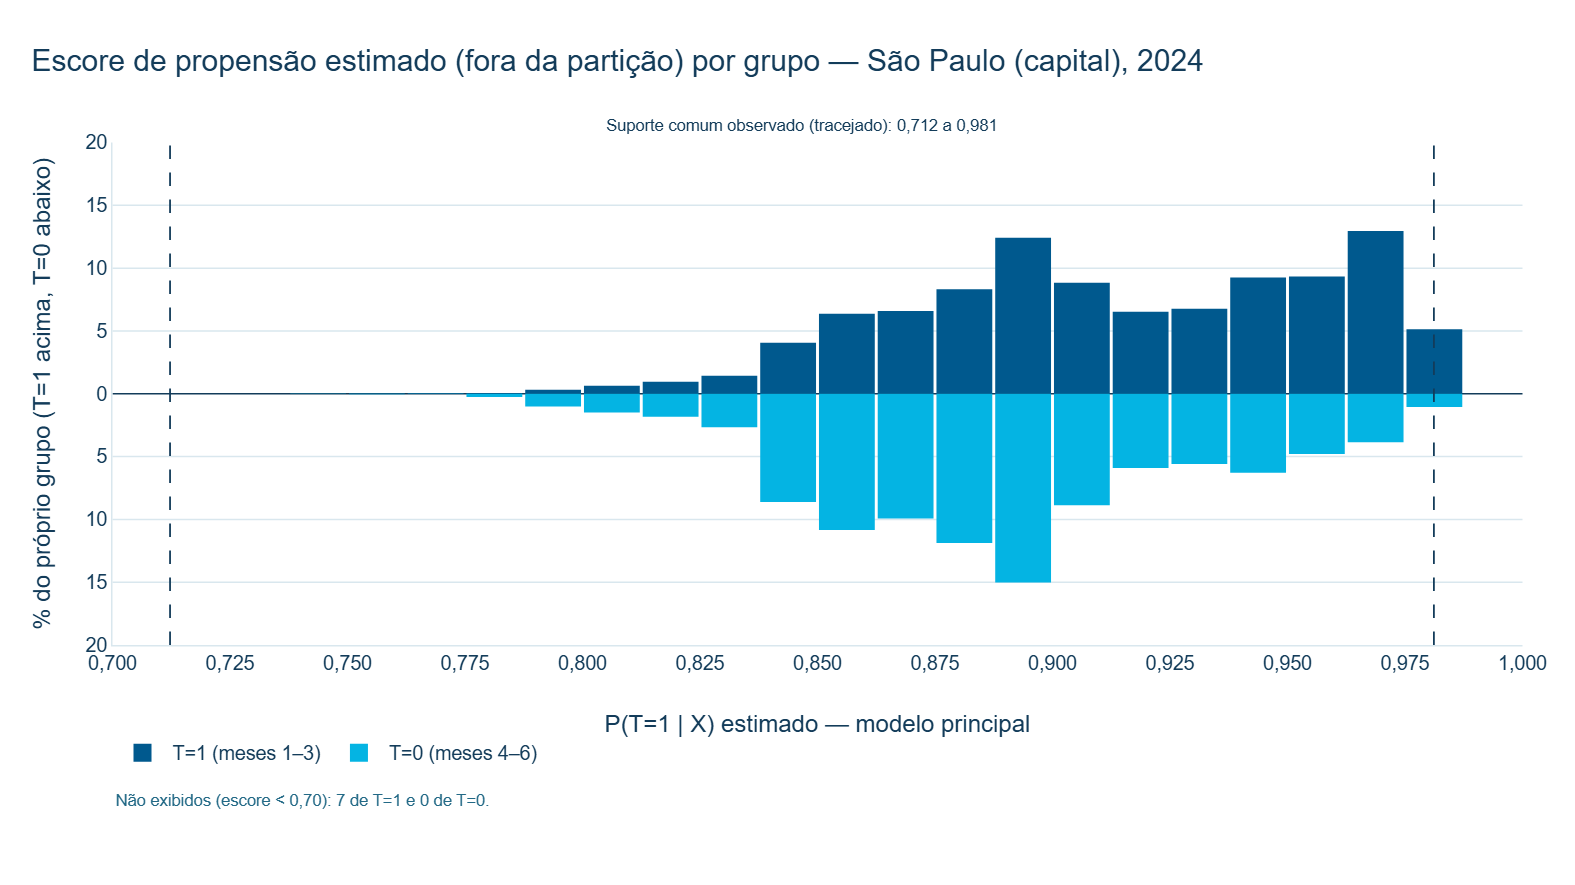

In [9]:
e = escores["principal"]
# Histograma espelhado: T=1 acima e T=0 abaixo do zero, cada um em % do próprio grupo.
EIXO_MIN, LARGURA_BARRA = 0.70, LARGURA_FAIXA / 2
bordas = np.round(np.arange(EIXO_MIN, 1 + LARGURA_BARRA / 2, LARGURA_BARRA), 4)
centros = (bordas[:-1] + bordas[1:]) / 2
omitidos = {v: int(((e < EIXO_MIN) & (t_arr == v)).sum()) for v in (1, 0)}
fig_ps = go.Figure()
for valor, sinal, nome, cor in [(1, 1, "T=1 (meses 1–3)", CORES_IPT["AZUL_PRINCIPAL"]),
                                (0, -1, "T=0 (meses 4–6)", CORES_IPT["CIANO"])]:
    contagem, _ = np.histogram(e[t_arr == valor], bins=bordas)
    pct_grupo = 100 * contagem / (t_arr == valor).sum()
    fig_ps.add_bar(
        x=centros, y=sinal * pct_grupo, width=LARGURA_BARRA * 0.95, name=nome,
        marker=dict(color=cor), customdata=np.c_[pct_grupo, contagem],
        hovertemplate="Escore %{x:.3f}<br>%{customdata[0]:.2f}% do grupo"
                      "<br>n = %{customdata[1]:,.0f}<extra>" + nome + "</extra>")
for limite in (sc["inferior"], sc["superior"]):
    fig_ps.add_vline(x=limite, line=dict(color=CORES_IPT["AZUL_ESCURO"], dash="dash", width=1.2))
fig_ps.add_annotation(x=(sc["inferior"] + sc["superior"]) / 2, y=1.06, yref="paper", showarrow=False,
                      text=f"Suporte comum observado (tracejado): {fmt(sc['inferior'], 3)} a {fmt(sc['superior'], 3)}",
                      font=dict(size=11, color=CORES_IPT["AZUL_ESCURO"]))
fig_ps.add_annotation(x=0, xref="paper", xanchor="left", y=-0.33, yref="paper", showarrow=False,
                      text=f"Não exibidos (escore < {fmt(EIXO_MIN, 2)}): {fmt(omitidos[1])} de T=1 e {fmt(omitidos[0])} de T=0.",
                      font=dict(size=11, color=CORES_IPT["AZUL_MEDIO"]))
aplicar_tema_base(fig_ps, "Escore de propensão estimado (fora da partição) por grupo — São Paulo (capital), 2024")
limite_y = np.ceil(max(abs(v) for tr in fig_ps.data for v in tr.y) / 5) * 5
marcas = np.arange(-limite_y, limite_y + 1, 5)
fig_ps.update_layout(barmode="relative", width=1050, height=590, separators=",.",
                     margin=dict(l=75, r=35, t=95, b=160), legend=dict(orientation="h", y=-0.17, x=0))
fig_ps.update_xaxes(title="P(T=1 | X) estimado — modelo principal", range=[EIXO_MIN, 1.0], dtick=0.025,
                    tickformat=".3f")
fig_ps.update_yaxes(title="% do próprio grupo (T=1 acima, T=0 abaixo)", range=[-limite_y, limite_y],
                    tickvals=marcas, ticktext=[fmt(abs(v)) for v in marcas], zeroline=True,
                    zerolinecolor=CORES_IPT["AZUL_ESCURO"])
exibir_plotly(fig_ps)

### Faixas com pouca representação de um dos grupos

Faixas de 0,025 do escore principal. A proporção de T=0 na faixa mostra como a composição muda ao longo do escore; faixas sinalizadas têm menos de 20 registros em algum grupo.

In [10]:
faixas = principal.query("bloco == 'faixa'").copy()
display(pd.DataFrame({
    "T=1 n (% do grupo)": [f"{fmt(r.n_t1)} ({fmt(r.pct_t1, 2)}%)" for r in faixas.itertuples()],
    "T=0 n (% do grupo)": [f"{fmt(r.n_t0)} ({fmt(r.pct_t0, 2)}%)" for r in faixas.itertuples()],
    "% T=0 na faixa": [fmt(100 * v, 1) for v in faixas.prop_t0_na_faixa],
    "Pouca representação": ["sim" if v else "" for v in faixas.pouca_representacao],
}, index=faixas.item.rename("Faixa do escore")))

def comparar_modelo(m):
    r = resumo_ps.loc[resumo_ps.modelo.eq(m)]
    g = overlap[m]["grupos"]
    alto = r.loc[r.item.eq("e>0,95")].iloc[0]
    fora = r.loc[r.bloco.eq("suporte_comum")]
    return {
        "AUC fora da partição": fmt(ajustes[m]["auc_oof"], 3),
        "Mínimo T=1 / T=0": f"{fmt(g['tratado']['min'], 3)} / {fmt(g['controle']['min'], 3)}",
        "Máximo T=1 / T=0": f"{fmt(g['tratado']['max'], 3)} / {fmt(g['controle']['max'], 3)}",
        "Registros em e>0,95 (T=1 / T=0)": f"{fmt(alto.n_t1)} / {fmt(alto.n_t0)}",
        "Fora do suporte comum (T=1 / T=0)": f"{fmt(fora.n_t1.sum())} / {fmt(fora.n_t0.sum())}",
        "Faixas com pouca representação": int(r.loc[r.bloco.eq("faixa"), "pouca_representacao"].sum()),
    }
comparacao = pd.DataFrame({m: comparar_modelo(m) for m in modelos})
display(Markdown("**Principal versus sensibilidade sem situação conjugal e perdas fetais**"))
display(comparacao)

resumo_ps.round(6).to_csv(CSV_PROPENSITY, sep=";", index=False, encoding="utf-8-sig")
print("Gravado:", CSV_PROPENSITY.relative_to(raiz).as_posix(), "—", len(resumo_ps), "linhas")

,T=1 n (% do grupo),T=0 n (% do grupo),% T=0 na faixa,Pouca representação
Faixa do escore,,,,
"0,500–0,525","1 (0,00%)","0 (0,00%)","0,0",sim
"0,650–0,675","1 (0,00%)","0 (0,00%)","0,0",sim
"0,675–0,700","5 (0,00%)","0 (0,00%)","0,0",sim
"0,700–0,725","6 (0,01%)","1 (0,01%)","14,3",sim
"0,725–0,750","10 (0,01%)","3 (0,03%)","23,1",sim
"0,750–0,775","50 (0,05%)","5 (0,05%)","9,1",sim
"0,775–0,800","393 (0,38%)","129 (1,27%)","24,7",
"0,800–0,825","1.657 (1,58%)","336 (3,32%)","16,9",
"0,825–0,850","5.734 (5,48%)","1.140 (11,27%)","16,6",


**Principal versus sensibilidade sem situação conjugal e perdas fetais**

,principal,sensibilidade_nucleo
AUC fora da partição,"0,655","0,637"
Mínimo T=1 / T=0,"0,514 / 0,712","0,532 / 0,738"
Máximo T=1 / T=0,"0,986 / 0,981","0,986 / 0,980"
"Registros em e>0,95 (T=1 / T=0)",28.683 / 982,29.405 / 1.075
Fora do suporte comum (T=1 / T=0),125 / 0,44 / 0
Faixas com pouca representação,6,6


Gravado: outputs/comparabilidade_sp_capital_2024/resumo_propensity_2024.csv — 66 linhas


## 7. Interpretação

Os números abaixo são recalculados a partir dos resultados desta execução.

In [11]:
top = resumo.head(3)
p = principal.set_index("item")
fs = faixas.loc[faixas.pouca_representacao]
abaixo, acima = p.loc["abaixo_do_suporte_comum"], p.loc["acima_do_suporte_comum"]
alto = p.loc["e>0,95"]
g0 = overlap["principal"]["grupos"]["controle"]
odds_max_controle = g0["max"] / (1 - g0["max"])
esc = balanco.set_index(["variavel", "nivel"])
def descrever(r):
    if r.variavel == "IDADEMAE_NUM":
        return f"idade materna (|SMD| da média {fmt(r.smd_abs, 2)})"
    return f"{r.rotulo_variavel.lower()} (|SMD| máximo {fmt(r.smd_abs, 2)}, nível {r.nivel_mais_desequilibrado.lower()})"
cauda = "todas na cauda inferior" if (fs.limite_superior <= np.median(e)).all() else "em mais de uma região"
ultima = faixas.iloc[-1]
def linha_nivel(v, n):
    r = esc.loc[(v, n)]
    return f"{fmt(r.pct_t1, 1)}% em T=1 versus {fmt(r.pct_t0, 1)}% em T=0 (SMD {fmt(r.smd, 2)})"

texto = f"""
**1. Covariáveis mais desequilibradas.** Antes de qualquer ajuste: {', '.join(descrever(r) for r in top.itertuples())}. Superior completo: {linha_nivel('ESCOLARIDADE_MAE', '5')}; casada: {linha_nivel('SITUACAO_CONJUGAL', '2')}; solteira: {linha_nivel('SITUACAO_CONJUGAL', '1')}. A idade média difere {fmt(balanco.diferenca.iloc[0], 1)} ano(s) (SMD {fmt(smd_idade, 2)}); a faixa 10–19 anos é a mais concentrada em T=0 ({linha_nivel('IDADE_FAIXA', '10-19')}). Raça/cor e paridade ficam entre 0,1 e 0,2; perdas fetais anteriores ficam abaixo de 0,1 (|SMD| {fmt(resumo.set_index('variavel').smd_abs['PERDAS_FETAIS_CAT'], 3)}). O padrão é coerente com um gradiente socioeconômico: início tardio concentra-se em mães mais jovens, com menor escolaridade e sem companheiro formal.

**2. Sobreposição.** Sim, nas covariáveis incluídas. Os escores estimados vão de {fmt(overlap['principal']['grupos']['tratado']['min'], 3)} a {fmt(overlap['principal']['grupos']['tratado']['max'], 3)} em T=1 e de {fmt(g0['min'], 3)} a {fmt(g0['max'], 3)} em T=0; nenhum registro fica abaixo de 0,05 ou acima de 0,99. A AUC fora da partição de {fmt(ajustes['principal']['auc_oof'], 3)} indica discriminação apenas modesta: as covariáveis observadas explicam pouco do momento de início. Isso favorece o suporte comum, mas também significa que boa parte da variação no início do pré-natal se deve a fatores **não registrados** no SINASC.

**3. Regiões com pouca representação.** {fmt(len(fs))} faixa(s) de 0,025 com menos de {MIN_N_FAIXA} registros em algum grupo ({', '.join(fs.item)}), {cauda}, com {fmt(fs.n_t1.sum())} tratados e {fmt(fs.n_t0.sum())} controles no total. Fora do suporte comum observado: {fmt(abaixo.n_t1)} tratados abaixo do mínimo dos controles e {fmt(acima.n_t1)} tratados acima do máximo dos controles ({fmt(abaixo.n_t0 + acima.n_t0)} controles fora). A região crítica é a cauda superior: acima de 0,95 estão {fmt(alto.n_t1)} tratados ({fmt(alto.pct_t1, 1)}% de T=1) e {fmt(alto.n_t0)} controles ({fmt(alto.pct_t0, 1)}% de T=0) — controles existem, mas são relativamente escassos ali: na última faixa ({ultima["item"]}) há {fmt(ultima.n_t1)} tratados para {fmt(ultima.n_t0)} controles ({fmt(100 * ultima.prop_t0_na_faixa, 1)}% de T=0, contra {fmt(100 * n_t0 / n_total, 1)}% na população). Na sensibilidade sem situação conjugal e perdas fetais, o quadro é semelhante (AUC {fmt(ajustes['sensibilidade_nucleo']['auc_oof'], 3)}).

**4. Implicações para o desenho de estimação.** O suporte observado não impede a estimação nesta população. Como o escore se concentra perto de 1, controles com escore alto teriam razão de chances $e/(1-e)$ de até ≈ {fmt(odds_max_controle, 0)} sob ponderação voltada aos tratados, e o termo $1/(1-e)$ de estimadores como AIPW ficaria igualmente grande para esses controles. O próximo desenho deve, portanto, reportar a distribuição desses pesos, a sensibilidade a recortes de suporte pré-especificados (a regra simétrica 0,05–0,95 retiraria {fmt(alto.n_t1)} tratados — {fmt(alto.pct_t1, 1)}% de T=1 — e {fmt(alto.n_t0)} controles, o que mostra que limites simétricos convencionais não servem quando $P(T=1)$ marginal é ≈ {fmt(n_t1 / n_total, 2)}) e a escolha explícita do estimando (ATE versus ATT), sem decidir aqui uma nova versão. Os desequilíbrios de escolaridade, situação conjugal e idade exigem que essas três covariáveis estejam no ajuste, e a idade talvez mereça forma não linear (a diferença se concentra nas adolescentes).

**5. O que permanece sem resposta.**
- *Confundimento não observado:* renda, cobertura por plano privado versus SUS, gravidez planejada, desejo da gestação, tabagismo, condições clínicas prévias e acesso geográfico à unidade de saúde não estão no SINASC e provavelmente afetam tanto o início do pré-natal quanto o peso ao nascer. Balanço e suporte comum aqui nada dizem sobre essas variáveis.
- *Temporalidade da exposição:* `MESPRENAT` é registrado no parto, por recordação ou transcrição do cartão. Gestações que terminam mais cedo têm menos tempo para "chegar" a um início tardio; restringir T=0 aos meses 4–6 atenua, mas não elimina, a ligação entre duração da gestação e classificação da exposição.
- *Temporalidade das covariáveis:* todas são registradas no parto; situação conjugal e escolaridade podem ter mudado depois do início do pré-natal.
- *Seleção:* apenas nascidos vivos; perdas fetais da gestação atual não entram na população.
- *Positividade estrutural:* o suporte foi avaliado só nas covariáveis incluídas. A queda da proporção de T=0 ao longo dos anos motiva esta verificação, mas não é, por si só, violação de positividade.
"""
display(Markdown(texto))


**1. Covariáveis mais desequilibradas.** Antes de qualquer ajuste: escolaridade (|SMD| máximo 0,45, nível superior completo), situação conjugal (|SMD| máximo 0,42, nível casada), idade materna (|SMD| da média 0,27). Superior completo: 31,1% em T=1 versus 12,9% em T=0 (SMD 0,45); casada: 36,5% em T=1 versus 18,1% em T=0 (SMD 0,42); solteira: 45,3% em T=1 versus 59,1% em T=0 (SMD -0,28). A idade média difere 1,8 ano(s) (SMD 0,27); a faixa 10–19 anos é a mais concentrada em T=0 (6,6% em T=1 versus 11,9% em T=0 (SMD -0,19)). Raça/cor e paridade ficam entre 0,1 e 0,2; perdas fetais anteriores ficam abaixo de 0,1 (|SMD| 0,041). O padrão é coerente com um gradiente socioeconômico: início tardio concentra-se em mães mais jovens, com menor escolaridade e sem companheiro formal.

**2. Sobreposição.** Sim, nas covariáveis incluídas. Os escores estimados vão de 0,514 a 0,986 em T=1 e de 0,712 a 0,981 em T=0; nenhum registro fica abaixo de 0,05 ou acima de 0,99. A AUC fora da partição de 0,655 indica discriminação apenas modesta: as covariáveis observadas explicam pouco do momento de início. Isso favorece o suporte comum, mas também significa que boa parte da variação no início do pré-natal se deve a fatores **não registrados** no SINASC.

**3. Regiões com pouca representação.** 6 faixa(s) de 0,025 com menos de 20 registros em algum grupo (0,500–0,525, 0,650–0,675, 0,675–0,700, 0,700–0,725, 0,725–0,750, 0,750–0,775), todas na cauda inferior, com 73 tratados e 9 controles no total. Fora do suporte comum observado: 10 tratados abaixo do mínimo dos controles e 115 tratados acima do máximo dos controles (0 controles fora). A região crítica é a cauda superior: acima de 0,95 estão 28.683 tratados (27,4% de T=1) e 982 controles (9,7% de T=0) — controles existem, mas são relativamente escassos ali: na última faixa (0,975–1,000) há 5.366 tratados para 106 controles (1,9% de T=0, contra 8,8% na população). Na sensibilidade sem situação conjugal e perdas fetais, o quadro é semelhante (AUC 0,637).

**4. Implicações para o desenho de estimação.** O suporte observado não impede a estimação nesta população. Como o escore se concentra perto de 1, controles com escore alto teriam razão de chances $e/(1-e)$ de até ≈ 52 sob ponderação voltada aos tratados, e o termo $1/(1-e)$ de estimadores como AIPW ficaria igualmente grande para esses controles. O próximo desenho deve, portanto, reportar a distribuição desses pesos, a sensibilidade a recortes de suporte pré-especificados (a regra simétrica 0,05–0,95 retiraria 28.683 tratados — 27,4% de T=1 — e 982 controles, o que mostra que limites simétricos convencionais não servem quando $P(T=1)$ marginal é ≈ 0,91) e a escolha explícita do estimando (ATE versus ATT), sem decidir aqui uma nova versão. Os desequilíbrios de escolaridade, situação conjugal e idade exigem que essas três covariáveis estejam no ajuste, e a idade talvez mereça forma não linear (a diferença se concentra nas adolescentes).

**5. O que permanece sem resposta.**
- *Confundimento não observado:* renda, cobertura por plano privado versus SUS, gravidez planejada, desejo da gestação, tabagismo, condições clínicas prévias e acesso geográfico à unidade de saúde não estão no SINASC e provavelmente afetam tanto o início do pré-natal quanto o peso ao nascer. Balanço e suporte comum aqui nada dizem sobre essas variáveis.
- *Temporalidade da exposição:* `MESPRENAT` é registrado no parto, por recordação ou transcrição do cartão. Gestações que terminam mais cedo têm menos tempo para "chegar" a um início tardio; restringir T=0 aos meses 4–6 atenua, mas não elimina, a ligação entre duração da gestação e classificação da exposição.
- *Temporalidade das covariáveis:* todas são registradas no parto; situação conjugal e escolaridade podem ter mudado depois do início do pré-natal.
- *Seleção:* apenas nascidos vivos; perdas fetais da gestação atual não entram na população.
- *Positividade estrutural:* o suporte foi avaliado só nas covariáveis incluídas. A queda da proporção de T=0 ao longo dos anos motiva esta verificação, mas não é, por si só, violação de positividade.


## 8. Conclusão e próximos passos possíveis

- **Diagnóstico:** na capital paulista em 2024, os grupos diferem de forma relevante em escolaridade, situação conjugal e idade, o que confirma a necessidade de ajuste. No conjunto de covariáveis do contrato, o suporte comum é amplo e não há escores extremos. A limitação central não é a positividade observada, e sim o confundimento não observado e a temporalidade da exposição.
- **Próximos passos possíveis (não executados aqui):**
  1. revisar com a orientadora o conjunto de ajuste (diagrama causal curto), decidindo sobre situação conjugal, perdas fetais, forma funcional da idade e campos pré-exposição ainda não usados;
  2. pré-especificar o estimando (ATE ou ATT), a regra de recorte de suporte e os diagnósticos de pesos antes de qualquer estimação na capital;
  3. planejar uma análise de sensibilidade a confundimento não observado (por exemplo, valor E) e um controle negativo, quando houver candidato defensável.

Arquivos desta pasta: `balanco_covariaveis_2024.csv` (chave `variavel` + `tipo_linha` + `nivel`) e `resumo_propensity_2024.csv` (chave `modelo` + `bloco` + `item`); separador ";", decimal ponto, UTF-8 com BOM.

In [12]:
b = pd.read_csv(CSV_BALANCO, sep=";", encoding="utf-8-sig", dtype={"nivel": "string"})
r = pd.read_csv(CSV_PROPENSITY, sep=";", encoding="utf-8-sig")
assert not b.duplicated(["variavel", "tipo_linha", "nivel"]).any()
assert not r.duplicated(["modelo", "bloco", "item"]).any()
assert set(r.modelo) == set(modelos)
for v in CATEGORICAS + ["IDADE_FAIXA"]:
    niv = b.loc[b.variavel.eq(v)]
    assert niv.n_t1.sum() == n_t1 and niv.n_t0.sum() == n_t0, v
print(f"Validação final: {len(b)} linhas de balanço e {len(r)} linhas de resumo do escore;"
      " chaves únicas; níveis somam os totais de cada grupo.")
print(f"População analisada: {fmt(n_total)} nascimentos (T=1 {fmt(n_t1)}; T=0 {fmt(n_t0)}).")

Validação final: 29 linhas de balanço e 66 linhas de resumo do escore; chaves únicas; níveis somam os totais de cada grupo.
População analisada: 114.694 nascimentos (T=1 104.576; T=0 10.118).


## 9. Estimando e próxima estimação — proposta condicionada

**Decisão:** ATO restrito ao suporte comum é candidato principal; aprovação causal permanece pendente. ATE responde à pergunta populacional ampla; ATO exige aceitar uma população mais comparável. Desfecho: diferença de riscos de peso <2.500 g no nascimento, T=1 menos T=0.

**Evidência existente:** 114.694 elegíveis; 91,18% tratados. SMD máximos: escolaridade 0,452; situação conjugal 0,421; idade 0,270. Acima de e=0,95: 28.683 tratados/982 controles. Desequilíbrio numérico não implica, isoladamente, falta de positividade.

| Estimando | População-alvo e implicação |
|---|---|
| ATE | Todos os elegíveis B; poucos controles representam muitos tratados. Pesos 1/e e 1/(1−e) amplificam caudas. |
| ATT | Tratados; pesos 1 e e/(1−e). Controles chegariam a ≈52 no diagnóstico existente; não resolve a cauda superior. |
| ATO | Perfis ponderados por e(1−e), dentro do suporte adotado; pesos brutos 1−e e e são limitados. Muda o alvo, não representa todos os elegíveis. |

Fundamento: [Li, Morgan e Zaslavsky](https://arxiv.org/abs/1404.1785).

**Ajuste proposto:** idade linear+quadrática, escolaridade, raça/cor, paridade e perdas fetais anteriores. Confirmar manualmente histórico pré-gestação, códigos de perdas e escolaridade como aproximação pré-exposição. Situação conjugal fica fora do principal pela temporalidade incerta; adicioná-la como sensibilidade somente sob hipótese explícita de representar condição anterior. Reestimar e nessa alternativa muda também o alvo ATO. SMD/AUC não determinam inclusão nem comprovam ignorabilidade. UF constante excluída; consultas, parto, duração gestacional e outros mediadores não entram.

**Suporte:** após congelar X, definir R pela interseção dos intervalos de escores dos grupos, documentando perdas/perfis; no modelo existente excluiria 125 tratados/zero controles. ATO em R usa h=e(1−e)I(R). Extremos amostrais são diagnóstico operacional, não garantia de suporte multivariado. Não adotar automaticamente 0,05–0,95. Examinar balanço, concentração dos pesos e tamanho efetivo por grupo.

**Limites:** ajuste pode reduzir desequilíbrio observado e instabilidade; não recupera confundidores ausentes. Definir tempo zero comum antes do pré-natal: alcançar os meses 4–6 depende da duração gestacional; ajustar por duração ou restringir a nascimentos a termo não resolve. Seleção por nascimento vivo e faixa de peso é pós-exposição; o efeito em todas as gestações ou nos sobreviventes sob ambas estratégias não está identificado. [Viés de seleção por nascimento vivo](https://pmc.ncbi.nlm.nih.gov/articles/PMC4339763/).

**Próxima execução, após validação manual:** congelar desenho/X/R; atualizar escores somente se necessário; diagnosticar pesos/balanço/tamanho efetivo e, então, estimar riscos normalizados e diferença com IC95%, incorporando estimação dos escores. Sem justificativa temporal/seleção suficiente, interpretar como associação ajustada. Nenhuma execução nesta seção.